### Load Airport and Airline Abbreviations

In [52]:
import json

with open(r"data\\carriers.json", "r") as file:
    carriers = json.load(file)
print(carriers.get("AA", "Unknown Carrier"))

with open(r"data\\airports.json", "r") as file:
    airports = json.load(file)

print(airports.get("ATL", "Unknown Airport"))


American Airlines
Hartsfield International, Atlanta, GA


### Loading and Combining airport-airline wise CSVs into a single airport wise df

In [22]:
import pandas as pd
alaska_atl = pd.read_csv(r"data\atl-atlanta\alaska_atl_2025.csv")
american_atl = pd.read_csv(r"data\atl-atlanta\american_atl_2025.csv")
delta_atl = pd.read_csv(r"data\atl-atlanta\delta_atl_2025.csv")
frontier_atl = pd.read_csv(r"data\atl-atlanta\frontier_atl_2025.csv")
jetblue_atl = pd.read_csv(r"data\atl-atlanta\jetblue_atl_2025.csv")
southwest_atl = pd.read_csv(r"data\atl-atlanta\southwest_atl_2025.csv")
united_atl = pd.read_csv(r"data\atl-atlanta\united_atl_2025.csv")

alaska_lax= pd.read_csv(r"data\lax-los-angeles\alaska_lax_2025.csv")
american_lax = pd.read_csv(r"data\lax-los-angeles\american_lax_2025.csv")
delta_lax = pd.read_csv(r"data\lax-los-angeles\delta_lax_2025.csv")
frontier_lax = pd.read_csv(r"data\lax-los-angeles\frontier_lax_2025.csv")
jetblue_lax = pd.read_csv(r"data\lax-los-angeles\jetblue_lax_2025.csv") 
southwest_lax = pd.read_csv(r"data\lax-los-angeles\southwest_lax_2025.csv")
united_lax = pd.read_csv(r"data\lax-los-angeles\united_lax_2025.csv")

atlanta_airlines_list=[alaska_atl, american_atl, delta_atl, frontier_atl, jetblue_atl, southwest_atl, united_atl]
la_airlines_list=[alaska_lax, american_lax, delta_lax, frontier_lax, jetblue_lax, southwest_lax, united_lax]

In [29]:
atlanta_airlines= pd.concat(
    [
        alaska_atl,
        american_atl,
        delta_atl,
        frontier_atl,
        jetblue_atl,
        southwest_atl,
        united_atl,
    ],
    ignore_index=True,
)

# Insert Origin Airport between Tail Number and Destination Airport
atlanta_airlines.insert(
    atlanta_airlines.columns.get_loc("Destination Airport"),
    "Origin Airport",
    "ATL",
)

####

la_airlines= pd.concat(
    [
        alaska_lax,
        american_lax,
        delta_lax,
        frontier_lax,
        jetblue_lax,
        southwest_lax,
        united_lax,
    ],
    ignore_index=True,
)   

# Insert Origin Airport between Tail Number and Destination Airport
la_airlines.insert(
    la_airlines.columns.get_loc("Destination Airport"),
    "Origin Airport",
    "LAX",
)

atlanta_airlines.head()


,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2025,321,N428AS,ATL,SEA,18:39,18:36,343,344,-3,18:53,17,0,0,0,0,0
1,AS,01/01/2025,355,N588AS,ATL,SAN,17:19,17:16,284,297,-3,17:35,19,0,0,0,0,0
2,AS,01/01/2025,377,N278AK,ATL,SEA,07:04,06:55,343,336,-9,07:11,16,0,0,0,0,0
3,AS,01/01/2025,497,N562AS,ATL,SEA,15:27,15:22,344,338,-5,15:34,12,0,0,0,0,0
4,AS,01/01/2025,783,N263AK,ATL,PDX,19:59,20:07,319,343,8,20:23,16,8,0,24,0,0


In [30]:
la_airlines.head()

,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2025,6,N597AS,LAX,DCA,13:08,13:02,291,278,-6,13:21,19,0,0,0,0,0
1,AS,01/01/2025,193,N408AS,LAX,ANC,19:51,19:48,347,321,-3,20:02,14,0,0,0,0,0
2,AS,01/01/2025,284,N548AS,LAX,EWR,06:00,05:54,330,304,-6,06:14,20,0,0,0,0,0
3,AS,01/01/2025,286,N948AK,LAX,EWR,08:29,08:26,330,313,-3,08:55,29,0,0,0,0,0
4,AS,01/01/2025,288,N968AK,LAX,EWR,21:40,21:36,319,293,-4,21:52,16,0,0,0,0,0


In [24]:
print(atlanta_airlines.shape)
print(la_airlines.shape)

(292057, 18)
(140108, 18)


### Monthly Flight counts plot per airport

In [ ]:
import matplotlib.pyplot as plt

def plot_monthly_flight_counts(df):
    dates = pd.to_datetime(df["Date (MM/DD/YYYY)"], format="%m/%d/%Y", errors="coerce")
    counts = dates.dt.month.value_counts().reindex(range(1, 13), fill_value=0)

    ax = counts.plot(kind="bar", figsize=(10, 5))
    ax.set(
        title="Flights by Month",
        xlabel="Month",
        ylabel="Number of flights",
        xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    )
    plt.tight_layout()

    min_count, max_count = counts.min(), counts.max()
    for bar, value in zip(ax.patches, counts):
        if value == max_count:
            bar.set_color("green")
        elif value == min_count:
            bar.set_color("red")
    plt.show()

# Example:
for airline_df in atlanta_airlines_list:
    plot_monthly_flight_counts(airline_df)

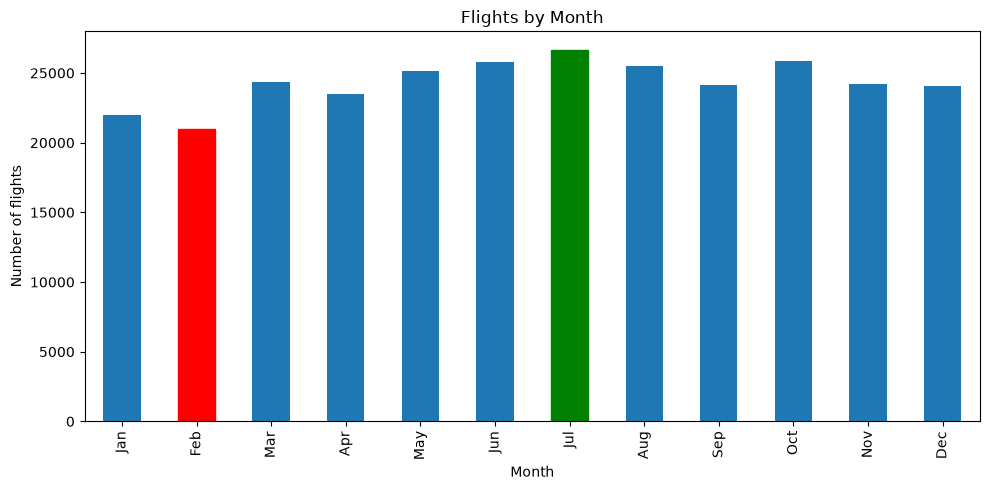

In [20]:
plot_monthly_flight_counts(atlanta_airlines)

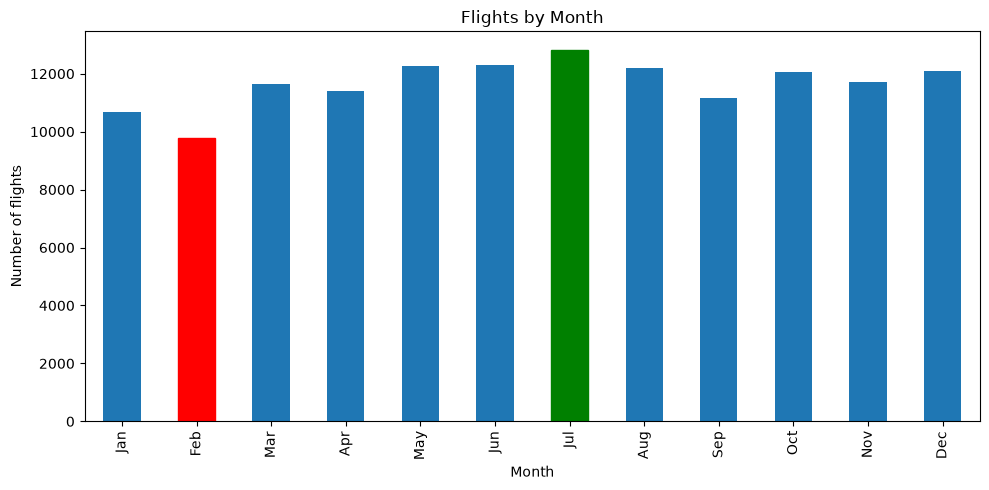

In [25]:
plot_monthly_flight_counts(la_airlines)

### Calculating punctuality rate of the Carriers (deriving the arrival delay(time) column)

In [31]:
atlanta_airlines.head()

,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2025,321,N428AS,ATL,SEA,18:39,18:36,343,344,-3,18:53,17,0,0,0,0,0
1,AS,01/01/2025,355,N588AS,ATL,SAN,17:19,17:16,284,297,-3,17:35,19,0,0,0,0,0
2,AS,01/01/2025,377,N278AK,ATL,SEA,07:04,06:55,343,336,-9,07:11,16,0,0,0,0,0
3,AS,01/01/2025,497,N562AS,ATL,SEA,15:27,15:22,344,338,-5,15:34,12,0,0,0,0,0
4,AS,01/01/2025,783,N263AK,ATL,PDX,19:59,20:07,319,343,8,20:23,16,8,0,24,0,0


In [56]:
minutes_per_flight = (365 * 24 * 60)/atlanta_airlines.shape[0] 
minutes_per_flight #1 flight every 1.8mins on average

1.7996486987129225

In [57]:
arrival_delay = (
    atlanta_airlines["Actual elapsed time (Minutes)"]
    - atlanta_airlines["Scheduled elapsed time (Minutes)"]
    + atlanta_airlines["Departure delay (Minutes)"]
)

airline_punctuality = (
    atlanta_airlines.assign(OnTime=arrival_delay <= 15)
    .groupby("Carrier Code")["OnTime"]
    .agg(on_time="sum", total="count")
)

for code, row in airline_punctuality.iterrows():
    airline_name = carriers.get(code, code)
    percentage = 100 * row["on_time"] / row["total"]
    print(
        f"{airline_name}: {int(row['on_time'])}/{int(row['total'])} "
        f"total on time ({percentage:.1f}%)"
    )

American Airlines: 5271/6834 total on time (77.1%)
Alaska Airlines: 1076/1532 total on time (70.2%)
JetBlue Airways: 1681/2267 total on time (74.2%)
Delta Air Lines: 184868/237184 total on time (77.9%)
Frontier Airlines: 9974/15624 total on time (63.8%)
United Airlines: 5683/7160 total on time (79.4%)
Southwest Airlines: 16926/21456 total on time (78.9%)


### Analyzing the destinations starting from an airport, coverage distribution and airline distribution to destinations

In [45]:
atlanta_airlines["Destination Airport"].value_counts()

Destination Airport
MCO    7587
LGA    7024
DFW    6149
TPA    5914
MIA    5748
       ... 
BGR      29
RAP      16
FAR       5
SBN       2
SHV       1
Name: count, Length: 139, dtype: int64

In [58]:
flights_by_destination_and_carrier = (
    atlanta_airlines
    .groupby(["Destination Airport", "Carrier Code"])
    .size()
    .unstack(fill_value=0)
)

for destination, counts in flights_by_destination_and_carrier.loc[
    flights_by_destination_and_carrier.sum(axis=1).sort_values(ascending=False).index
].iterrows():
    total = int(counts.sum())
    destination_name = airports.get(destination, destination)
    print(f"\n{destination_name} ({destination}) - total {total}")

    for carrier, count in counts[counts > 0].sort_values(ascending=False).items():
        carrier_name = carriers.get(carrier, carrier)
        print(f"  {carrier_name} ({carrier}) - {int(count)}")


Orlando International, Orlando, FL (MCO) - total 7587
  Delta Air Lines (DL) - 5375
  Southwest Airlines (WN) - 1188
  Frontier Airlines (F9) - 1024

LaGuardia, New York, NY (LGA) - total 7024
  Delta Air Lines (DL) - 4919
  Southwest Airlines (WN) - 1385
  Frontier Airlines (F9) - 720

Dallas/Ft.Worth International, Dallas/Ft. Worth, TX (DFW) - total 6149
  Delta Air Lines (DL) - 2802
  American Airlines (AA) - 2667
  Frontier Airlines (F9) - 680

Tampa International, Tampa, FL (TPA) - total 5914
  Delta Air Lines (DL) - 4332
  Southwest Airlines (WN) - 838
  Frontier Airlines (F9) - 744

Miami International, Miami, FL (MIA) - total 5748
  Delta Air Lines (DL) - 3317
  American Airlines (AA) - 1636
  Frontier Airlines (F9) - 689
  Southwest Airlines (WN) - 106

Denver International, Denver, CO (DEN) - total 5572
  Delta Air Lines (DL) - 2739
  Southwest Airlines (WN) - 1111
  United Airlines (UA) - 1077
  Frontier Airlines (F9) - 645

Newark International, Newark, NJ (EWR) - total 54

In [59]:
# Destinations served by each airline
destination_total = len(flights_by_destination_and_carrier)

coverage_by_airline = (flights_by_destination_and_carrier > 0).sum().sort_values(
    ascending=False
)

print(f"Airline destination coverage (out of {destination_total} destinations):")
for code, covered in coverage_by_airline.items():
    airline_name = carriers.get(code, code)
    print(f"{airline_name} ({code}): {covered}/{destination_total}")

# Number of airlines serving each destination, then count destinations per number
airlines_per_destination = (flights_by_destination_and_carrier > 0).sum(axis=1)
coverage_distribution = airlines_per_destination.value_counts().sort_index()

print("\nDestinations served by each number of airlines:")
for airline_count, destination_count in coverage_distribution.items():
    print(f"{airline_count} airline(s): {destination_count} destination(s)")

Airline destination coverage (out of 139 destinations):
Delta Air Lines (DL): 138/139
Frontier Airlines (F9): 47/139
Southwest Airlines (WN): 39/139
American Airlines (AA): 12/139
United Airlines (UA): 8/139
JetBlue Airways (B6): 3/139
Alaska Airlines (AS): 3/139

Destinations served by each number of airlines:
1 airline(s): 79 destination(s)
2 airline(s): 20 destination(s)
3 airline(s): 30 destination(s)
4 airline(s): 9 destination(s)
5 airline(s): 1 destination(s)


In [60]:
# if 79 airports are just covered by 1 airline, will the idea of padding hold here?say all 79 routes are just by Delta, will using this information help us in any way (can we see just that route different performances for the same airline? does this deviate from our plan/core study) if we are comparing between airlines? is our definition solely based on that padding?